In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
class Model(nn.Module):
    def __init__(self,in_features=4,h1=8,h2=9,out_features=3):
        super().__init__()
        self.fc1=nn.Linear(in_features,h1)
        self.fc2=nn.Linear(h1,h2)
        self.out=nn.Linear(h2,out_features)


    def forward(self,x):
        x=F.relu(self.fc1(x))
        x=F.relu(self.fc2(x))
        x=self.out(x)

        return x


In [3]:
torch.manual_seed(41)
## create an instance of model
model=Model()

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd

In [5]:
df=pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
df=df.drop('Id',axis=1)

In [7]:
df['Species'].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [8]:
df['Species']=df['Species'].replace('Iris-setosa',0.0)
df['Species']=df['Species'].replace('Iris-versicolor',1.0)
df['Species']=df['Species'].replace('Iris-virginica',2.0)

In [9]:
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [10]:
X=df.drop('Species',axis=1)
y=df['Species']

In [11]:
X=X.values
y = y.astype('int64')

In [12]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [13]:
y
y=y.values

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=41)

In [15]:
X_train=torch.FloatTensor(X_train)
X_test=torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [ ]:
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.01)



In [17]:
model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>

In [21]:
epochs=100
losses=[]
for i in range(epochs):
    ## go forward get prediction
    y_pred=model.forward(X_train) ## fitting


    ## measure the loss

    loss=criterion(y_pred,y_train)


    ## Track the losses
    losses.append(loss.detach().numpy())

    ## print every 10 epoches
    if i%10==0:
        print(f"Epoch: {i} and loss: {loss}")

    ## back propogation

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()





Epoch: 0 and loss: 0.052865754812955856
Epoch: 10 and loss: 0.04508380591869354
Epoch: 20 and loss: 0.0397995188832283
Epoch: 30 and loss: 0.03597070649266243
Epoch: 40 and loss: 0.0329371802508831
Epoch: 50 and loss: 0.0304193664342165
Epoch: 60 and loss: 0.02679518237709999
Epoch: 70 and loss: 0.023382510989904404
Epoch: 80 and loss: 0.020531879737973213
Epoch: 90 and loss: 0.018495608121156693


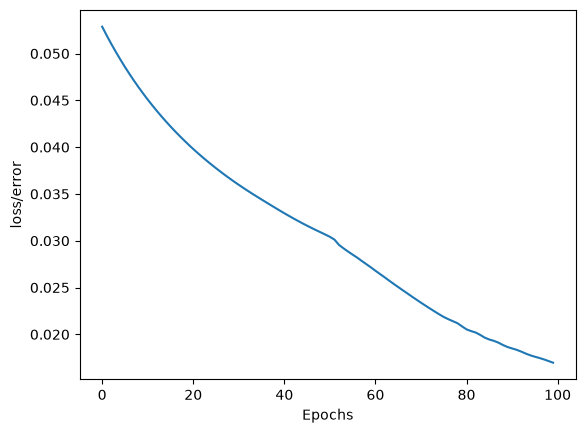

In [22]:
plt.plot(range(epochs),losses)
plt.ylabel("loss/error")
plt.xlabel("Epochs")
plt.show()

In [24]:
### Evaluvate the model on test data

with torch.no_grad():
    y_eval=model.forward(X_test)
    loss=criterion(y_eval,y_test)


In [25]:
loss

tensor(0.1816)

In [28]:
correct=0

with torch.no_grad():
    for i,data in enumerate(X_test):
        y_val=model.forward(data)

        print(f"{i+1} {str(y_val)} \t {y_test[i]}")

        if y_val.argmax().item()==y_test[i]:
            correct +=1

print(f"we got {correct}correct")

1 tensor([-7.1090,  3.8945,  9.0007]) 	 2
2 tensor([-9.7568,  1.8037, 15.7613]) 	 2
3 tensor([-10.9674,   2.8778,  16.6033]) 	 2
4 tensor([-3.7643,  8.0392, -1.2695]) 	 1
5 tensor([-9.0331,  3.5239, 12.6381]) 	 2
6 tensor([-1.8243,  8.6935, -5.3428]) 	 1
7 tensor([-6.8733,  4.9822,  7.3701]) 	 2
8 tensor([-3.6488,  8.2260, -1.6746]) 	 1
9 tensor([-7.9281,  4.2589,  9.9573]) 	 2
10 tensor([-10.4297,   1.8742,  16.8125]) 	 2
11 tensor([-6.4725,  5.1595,  6.5084]) 	 2
12 tensor([ 12.4419,   2.4570, -21.9054]) 	 0
13 tensor([ 11.4217,   2.2045, -19.9141]) 	 0
14 tensor([-0.1939,  6.9626, -6.0927]) 	 1
15 tensor([ 10.1568,   3.3059, -19.1093]) 	 0
16 tensor([-5.9766,  5.7990,  4.9672]) 	 2
17 tensor([ 11.2092,   2.5254, -19.9657]) 	 0
18 tensor([-6.8897,  4.2925,  8.1946]) 	 1
19 tensor([ 12.0366,   2.3664, -21.1265]) 	 0
20 tensor([  9.6811,   2.7818, -17.7343]) 	 0
21 tensor([-0.8225,  7.6358, -5.8092]) 	 1
22 tensor([-10.0604,   2.6577,  15.3367]) 	 2
23 tensor([ 10.3415,   3.2109, -19.3

In [33]:
new_iris=torch.tensor([4.7,5.2,3.3,8.8])

In [34]:
with torch.no_grad():
    print(model(new_iris))

tensor([-18.1142,  -2.3245,  34.2138])


In [35]:
## so unseen data predict it is iris-verginica

In [36]:
### save the model

torch.save(model.state_dict(),'iris_model.pt')

In [37]:
new_model=Model()
new_model.load_state_dict(torch.load('iris_model.pt'))

<All keys matched successfully>

In [38]:
new_model.eval()

Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)